In [ ]:
# 1. Install the ready-made tool-matching library
!pip install -q sentence-transformers

from sentence_transformers import SentenceTransformer, util

# 2. Load a ready-made model (No training needed!)
model = SentenceTransformer('all-MiniLM-L6-v2')

# 3. Create 1 user task and 4 tools (1 correct, 3 look-alike distractors)
query = "Send $50 to my friend John"

tools = [
    "send_money_api: Transfers money to another user's account.",          # CORRECT TOOL
    "request_money_api: Sends a payment request to another user.",         # DISTRACTOR 1
    "check_transfer_api: Checks if a money transfer to a friend worked.",  # DISTRACTOR 2
    "send_message_api: Sends a text message to a friend."                  # DISTRACTOR 3
]

# 4. Score how well each tool matches the user's task
query_vec = model.encode(query)
tool_vecs = model.encode(tools)
scores = util.cos_sim(query_vec, tool_vecs)[0]

# 5. Print the ranked shortlist
for score, tool in sorted(zip(scores, tools), reverse=True):
    print(f"Score: {score:.3f} | Tool: {tool}")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Score: 0.441 | Tool: send_money_api: Transfers money to another user's account.
Score: 0.408 | Tool: check_transfer_api: Checks if a money transfer to a friend worked.
Score: 0.392 | Tool: request_money_api: Sends a payment request to another user.
Score: 0.345 | Tool: send_message_api: Sends a text message to a friend.


In [ ]:
# --- STEP 3: EXPERIENCE MEMORY & FAILURE RECOVERY ---

# Let's make a slightly trickier distractor that ACTUALLY fools the baseline model:
tools_tricky = [
    "send_money_api: Transfers funds to a recipient account.",               # CORRECT TOOL
    "transfer_money_friend_api: Checks status of sending $50 to a friend.",  # TRICKY DISTRACTOR
    "request_money_api: Sends a payment request to another user."            # DISTRACTOR 2
]

query_1 = "Send $50 to my friend John"
q1_vec = model.encode(query_1)
tool_vecs = model.encode(tools_tricky)

# 1. BEFORE MEMORY (Attempt 1)
base_scores = util.cos_sim(q1_vec, tool_vecs)[0].tolist()
best_tool_attempt_1 = tools_tricky[base_scores.index(max(base_scores))]

print("=== ATTEMPT 1 (No Memory Yet) ===")
for s, t in sorted(zip(base_scores, tools_tricky), reverse=True):
    print(f"Score: {s:.3f} | {t}")
print(f"\nPicked Tool: {best_tool_attempt_1}")

# 2. CHECK IF IT FAILED & SAVE TO MEMORY (M)
experience_memory = []  # This is 'M' from Section 3.2 of your paper!
correct_tool = tools_tricky[0]

if best_tool_attempt_1 != correct_tool:
    print("❌ Tool Execution FAILED! Saving (query, failed_tool) to Experience Memory M...")
    experience_memory.append((query_1, best_tool_attempt_1))

# 3. TRY AGAIN ON A SIMILAR QUERY USING MEMORY PENALTY (Section 3.2 math)
query_2 = "Send $20 to my friend Sarah"
q2_vec = model.encode(query_2)
new_base_scores = util.cos_sim(q2_vec, tool_vecs)[0].tolist()

tau = 0.5     # Similarity threshold (τ) from your paper
lam = 0.3     # Penalty weight (λ) from your paper
updated_scores = []

for i, tool in enumerate(tools_tricky):
    s_qt = new_base_scores[i]

    # Check Experience Memory M for past failures on this specific tool
    pi_qt = 0.0
    for failed_query, failed_tool in experience_memory:
        if failed_tool == tool:
            sim = util.cos_sim(q2_vec, model.encode(failed_query)).item()
            if sim >= tau:
                pi_qt = max(pi_qt, sim)

    # Apply your paper's exact formula: s'(q,t) = s(q,t) - λ * π(q,t)
    s_prime = s_qt - (lam * pi_qt)
    updated_scores.append(s_prime)

print("\n=== ATTEMPT 2 ON SIMILAR QUERY (With Experience Memory) ===")
for s, t in sorted(zip(updated_scores, tools_tricky), reverse=True):
    print(f"New Score s'(q,t): {s:.3f} | {t}")
print(f"\n✅ Recovered! New Picked Tool: {tools_tricky[updated_scores.index(max(updated_scores))]}")

=== ATTEMPT 1 (No Memory Yet) ===
Score: 0.578 | transfer_money_friend_api: Checks status of sending $50 to a friend.
Score: 0.406 | send_money_api: Transfers funds to a recipient account.
Score: 0.392 | request_money_api: Sends a payment request to another user.

Picked Tool: transfer_money_friend_api: Checks status of sending $50 to a friend.
❌ Tool Execution FAILED! Saving (query, failed_tool) to Experience Memory M...

=== ATTEMPT 2 ON SIMILAR QUERY (With Experience Memory) ===
New Score s'(q,t): 0.426 | send_money_api: Transfers funds to a recipient account.
New Score s'(q,t): 0.363 | request_money_api: Sends a payment request to another user.
New Score s'(q,t): 0.313 | transfer_money_friend_api: Checks status of sending $50 to a friend.

✅ Recovered! New Picked Tool: send_money_api: Transfers funds to a recipient account.


In [ ]:
from sentence_transformers import SentenceTransformer, InputExample, losses
from torch.utils.data import DataLoader

# 1. Load the model
trained_model = SentenceTransformer('all-MiniLM-L6-v2')

# 2. Format training data using sentence-transformers' built-in InputExample:
# (Query = Anchor, Correct Tool = Positive, Distractors = Negatives)
train_examples = [
    InputExample(
        texts=[
            "Transfer $100 to my brother Mike",  # Anchor (Query)
            "send_money_api: Transfers funds to a recipient account.",  # Positive (Correct Tool t+)
            "transfer_money_friend_api: Checks status of sending $50 to a friend.",  # Negative (Distractor t-)
            "request_money_api: Sends a payment request to another user."   # Negative (Distractor t-)
        ]
    )
]

# 3. Create a DataLoader batch
train_dataloader = DataLoader(train_examples, shuffle=True, batch_size=1)

# 4. Use the built-in InfoNCE Loss (MultipleNegativesRankingLoss handles temperature θ automatically)
train_loss = losses.MultipleNegativesRankingLoss(trained_model)

print("=== TRAINING THE MODEL WITH SENTENCE-TRANSFORMERS TRAINER ===")
# 5. Train the model for 5 epochs
trained_model.fit(
    train_objectives=[(train_dataloader, train_loss)],
    epochs=5,
    show_progress_bar=True
)

# 6. TEST THE Newly Trained Model!
test_query = "Send $50 to my friend John"
train_tools = [
    "send_money_api: Transfers funds to a recipient account.",
    "transfer_money_friend_api: Checks status of sending $50 to a friend.",
    "request_money_api: Sends a payment request to another user."
]

q_test_vec = trained_model.encode(test_query)
t_test_vecs = trained_model.encode(train_tools)
new_scores = trained_model.similarity(q_test_vec, t_test_vecs)[0].tolist()

print("\n=== TEST AFTER TRAINING (Attempt 1 - Before Memory Even Steps In) ===")
for s, t in sorted(zip(new_scores, train_tools), reverse=True):
    print(f"Score: {s:.3f} | {t}")

/tmp/ipykernel_2410/3706207826.py:1: DeprecationWarning: Importing from 'sentence_transformers.losses' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.losses' instead.
  from sentence_transformers import SentenceTransformer, InputExample, losses


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

=== TRAINING THE MODEL WITH SENTENCE-TRANSFORMERS TRAINER ===


Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Step,Training Loss



=== TEST AFTER TRAINING (Attempt 1 - Before Memory Even Steps In) ===
Score: 0.578 | transfer_money_friend_api: Checks status of sending $50 to a friend.
Score: 0.406 | send_money_api: Transfers funds to a recipient account.
Score: 0.392 | request_money_api: Sends a payment request to another user.


In [ ]:
import torch
print("GPU:", torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE -> change runtime to T4!")
!pip install -q -U sentence-transformers datasets

GPU: True Tesla T4
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 760.7/760.7 kB 17.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 23.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 18.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.


In [ ]:
!git clone -q https://github.com/tangqiaoyu/ToolAlpaca.git
!find ToolAlpaca -name "*.json" | head -20

ToolAlpaca/data/eval_real.json
ToolAlpaca/data/train_data.json
ToolAlpaca/data/eval_simulated.json
ToolAlpaca/data/public_apis.json
ToolAlpaca/evalution_outputs/ToolAlpaca13b.json
ToolAlpaca/evalution_outputs/ToolAlpaca7b.json


In [ ]:
import json
d = json.load(open("/content/ToolAlpaca/data/public_apis.json"))
print(type(d), len(d))
print(json.dumps(d[0] if isinstance(d, list) else d, indent=2)[:2000])

<class 'dict'> 2
{
  "count": 1425,
  "entries": [
    {
      "API": "AdoptAPet",
      "Description": "Resource to help get pets adopted",
      "Auth": "apiKey",
      "HTTPS": true,
      "Cors": "yes",
      "Link": "https://www.adoptapet.com/public/apis/pet_list.html",
      "Category": "Animals"
    },
    {
      "API": "Axolotl",
      "Description": "Collection of axolotl pictures and facts",
      "Auth": "",
      "HTTPS": true,
      "Cors": "no",
      "Link": "https://theaxolotlapi.netlify.app/",
      "Category": "Animals"
    },
    {
      "API": "Cat Facts",
      "Description": "Daily cat facts",
      "Auth": "",
      "HTTPS": true,
      "Cors": "no",
      "Link": "https://alexwohlbruck.github.io/cat-facts/",
      "Category": "Animals"
    },
    {
      "API": "Cataas",
      "Description": "Cat as a service (cats pictures and gifs)",
      "Auth": "",
      "HTTPS": true,
      "Cors": "no",
      "Link": "https://cataas.com/",
      "Category": "Animals"
   

In [ ]:
import json
d = json.load(open("/content/ToolAlpaca/data/train_data.json"))
print(list(d[0].keys()))
for k, v in d[0].items():
    if k in ("Introduction", "Functions", "Documentation", "NLDocumentation"):
        continue
    print("\n###", k, type(v).__name__)
    print(str(v)[:700])

['Name', 'Description', 'Link', 'Category', 'Introduction', 'Functions', 'Documentation', 'NLDocumentation', 'Function_Description', 'Function_Projection', 'Instructions', 'Instances']

### Name str
Httpbin

### Description str
A Simple HTTP Request & Response Service

### Link str
https://httpbin.org/

### Category str
Development

### Function_Description dict
{'sendHttpRequest': 'Send an HTTP request with the specified method, headers, and data to the Httpbin API for testing purposes.\nParameters: {"method": "Required. string. One of: [GET, POST, PUT, DELETE, HEAD, PATCH]. The HTTP method to use (GET, POST, PUT, DELETE, HEAD, or PATCH).", "url": "Required. string. The endpoint URL to send the request to.", "headers": "Object.  A key-value pair of headers to include in the request.", "data": "Object.  A key-value pair of data to include in the request body."}\nOutput: Successful response.\n - Format: application/json\n - Structure: Object{response: Object{status_code, headers: Object

In [ ]:
import json, random
d = json.load(open("/content/ToolAlpaca/data/train_data.json"))

# 1. Tool pool: every function from every API = one "tool"
tools = {}  # tool_id -> text the encoder will see
for api in d:
    for fname, desc in api["Function_Description"].items():
        short = desc.split("\nParameters:")[0].strip()
        tools[f'{api["Name"]}::{fname}'] = f"{fname}: {short}"

# 2. Queries with exactly ONE correct tool
data, skipped = [], 0
for api in d:
    for inst in api["Instances"]:
        try:
            used = {step[0][0] for step in inst["intermediate_steps"]}
        except Exception:
            used = set()
        if len(used) != 1:      # skip multi-tool / empty queries
            skipped += 1
            continue
        tid = f'{api["Name"]}::{used.pop()}'
        if tid in tools:
            data.append({"query": inst["input"], "tool_id": tid, "api": api["Name"]})
        else:
            skipped += 1

print("Total tools:", len(tools))
print("Usable queries:", len(data), "| skipped:", skipped)
print("APIs covered:", len({x['api'] for x in data}))
ex = random.choice(data)
print("\nQUERY:", ex["query"][:200])
print("CORRECT TOOL:", tools[ex["tool_id"]][:200])

Total tools: 2695
Usable queries: 2643 | skipped: 1612
APIs covered: 380

QUERY: Please provide me with the status of the trademark application for "Starbucks".
CORRECT TOOL: searchTrademark: This function allows users to search for trademarks based on a keyword or phrase.


In [ ]:
import random, torch
from sentence_transformers import (SentenceTransformer, SentenceTransformerTrainer,
                                   SentenceTransformerTrainingArguments, losses)
from sentence_transformers.training_args import BatchSamplers
from datasets import Dataset
random.seed(42)

# ---- 1. split by API ----
apis = sorted({x["api"] for x in data}); random.shuffle(apis)
n = len(apis); split_of = {}
for i, a in enumerate(apis):
    split_of[a] = "train" if i < 0.7*n else "val" if i < 0.85*n else "test"
splits = {s: [x for x in data if split_of[x["api"]] == s] for s in ("train","val","test")}
pool   = {s: [t for t in tools if split_of.get(t.split("::")[0]) == s] for s in splits}
print({s: (len(splits[s]), "queries", len(pool[s]), "tools") for s in splits})

# ---- 2. mine distractors (nearest look-alike tools) ----
base = SentenceTransformer("all-MiniLM-L6-v2", device="cuda")
def mine(split, k=30):
    ids = pool[split]
    emb = base.encode([tools[t] for t in ids], convert_to_tensor=True,
                      normalize_embeddings=True, batch_size=128)
    sim = emb @ emb.T
    sim.fill_diagonal_(-1)
    top = sim.topk(k, dim=1).indices.cpu().numpy()
    return {ids[i]: [ids[j] for j in top[i]] for i in range(len(ids))}
neighbors = {s: mine(s) for s in splits}

# ---- 3. training data: (query, correct tool, 3 hard negatives) ----
rows = {"anchor": [], "positive": [], "neg1": [], "neg2": [], "neg3": []}
for x in splits["train"]:
    negs = random.sample(neighbors["train"][x["tool_id"]][:10], 3)
    rows["anchor"].append(x["query"]); rows["positive"].append(tools[x["tool_id"]])
    for j, ng in enumerate(negs, 1): rows[f"neg{j}"].append(tools[ng])
train_ds = Dataset.from_dict(rows)

# ---- 4. train ----
model = SentenceTransformer("all-MiniLM-L6-v2", device="cuda")
loss = losses.MultipleNegativesRankingLoss(model)
args = SentenceTransformerTrainingArguments(
    output_dir="enc_out", num_train_epochs=3, per_device_train_batch_size=32,
    learning_rate=2e-5, warmup_ratio=0.1, fp16=True,
    batch_sampler=BatchSamplers.NO_DUPLICATES,
    logging_steps=20, save_strategy="no", report_to="none")
SentenceTransformerTrainer(model=model, args=args, train_dataset=train_ds, loss=loss).train()

# ---- 5. evaluate: correct tool + k distractors, rank by cosine ----
def evaluate(m, split, name, ks=(10, 20, 30)):
    qs, ids = splits[split], pool[split]
    q = m.encode([x["query"] for x in qs], convert_to_tensor=True,
                 normalize_embeddings=True, batch_size=128)
    t = m.encode([tools[i] for i in ids], convert_to_tensor=True,
                 normalize_embeddings=True, batch_size=128)
    idx = {tid: i for i, tid in enumerate(ids)}
    for k in ks:
        top1 = r3 = 0
        for qi, x in enumerate(qs):
            cands = [x["tool_id"]] + neighbors[split][x["tool_id"]][:k]
            sc = q[qi] @ t[[idx[c] for c in cands]].T
            rank = (sc > sc[0]).sum().item()
            top1 += rank == 0; r3 += rank < 3
        print(f"{name:8s} +{k:2d} distractors | Top-1: {top1/len(qs):.3f} | Recall@3: {r3/len(qs):.3f}")

print("\n=== TEST SET (unseen APIs) ===")
evaluate(base,  "test", "BASE")
evaluate(model, "test", "TRAINED")

/tmp/ipykernel_324/3222042821.py:2: DeprecationWarning: Importing from 'sentence_transformers.losses' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.losses' instead.
  from sentence_transformers import (SentenceTransformer, SentenceTransformerTrainer,
/tmp/ipykernel_324/3222042821.py:4: DeprecationWarning: Importing from 'sentence_transformers.training_args' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.training_args' instead.
  from sentence_transformers.training_args import BatchSamplers


{'train': (1874, 'queries', 1599, 'tools'), 'val': (375, 'queries', 330, 'tools'), 'test': (394, 'queries', 334, 'tools')}


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

... (9 outputs left out)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

Step,Training Loss
20,1.018270
40,0.739582
60,0.635475
80,0.465752
100,0.547442
120,0.476419
140,0.461017
160,0.385156



=== TEST SET (unseen APIs) ===
BASE     +10 distractors | Top-1: 0.657 | Recall@3: 0.888
BASE     +20 distractors | Top-1: 0.635 | Recall@3: 0.871
BASE     +30 distractors | Top-1: 0.632 | Recall@3: 0.855
TRAINED  +10 distractors | Top-1: 0.728 | Recall@3: 0.914
TRAINED  +20 distractors | Top-1: 0.718 | Recall@3: 0.901
TRAINED  +30 distractors | Top-1: 0.713 | Recall@3: 0.888


In [ ]:
def run(m, split, k, lam, tau, R=3, use_mem=True):
    qs, ids = splits[split], pool[split]
    idx = {t: i for i, t in enumerate(ids)}
    Q = m.encode([x["query"] for x in qs], convert_to_tensor=True, normalize_embeddings=True, batch_size=128)
    T = m.encode([tools[i] for i in ids], convert_to_tensor=True, normalize_embeddings=True, batch_size=128)
    order = list(range(len(qs))); random.Random(0).shuffle(order)
    mem = {}  # tool_id -> query vectors it failed on  (this is M)
    first = succ = att = rep = 0
    for qi in order:
        x = qs[qi]
        cands = [x["tool_id"]] + neighbors[split][x["tool_id"]][:k]   # cands[0] = correct
        sc = Q[qi] @ T[[idx[c] for c in cands]].T
        for a in range(1, R + 1):
            s2, pis = sc.clone(), []
            for j, c in enumerate(cands):
                p = 0.0
                if use_mem and c in mem:
                    p = (torch.stack(mem[c]) @ Q[qi]).max().item()
                    p = p if p >= tau else 0.0
                s2[j] -= lam * p; pis.append(p)
            j = int(s2.argmax())
            if j == 0:
                succ += 1; att += a; first += (a == 1); break
            if a == 1 and pis[j] > 0: rep += 1       # repeated a known mistake
            if not use_mem:
                att += R; break
            mem.setdefault(cands[j], []).append(Q[qi])   # store failure
            if a == R: att += R
    n = len(qs)
    return dict(top1=first/n, succ_at_R=succ/n, avg_attempts=att/n, repeat_err=rep/n)

# ---- tune λ, τ on VAL ----
best = None
for lam in (0.1, 0.3, 0.5, 1.0):
    for tau in (0.5, 0.7, 0.8):
        r = run(model, "val", 30, lam, tau)
        print(f"lam={lam} tau={tau} | {r}")
        if best is None or (r["succ_at_R"], r["top1"]) > best[0]:
            best = ((r["succ_at_R"], r["top1"]), lam, tau)
_, LAM, TAU = best
print("\nBEST on val -> lam:", LAM, "tau:", TAU)

# ---- TEST ----
print("\n=== TEST ===")
for k in (10, 20, 30):
    print(f"+{k} Baseline:", run(model, "test", k, 0, 0, use_mem=False))
    print(f"+{k} E1 memory:", run(model, "test", k, LAM, TAU))

lam=0.1 tau=0.5 | {'top1': 0.8106666666666666, 'succ_at_R': 0.8986666666666666, 'avg_attempts': 1.3146666666666667, 'repeat_err': 0.034666666666666665}
lam=0.1 tau=0.7 | {'top1': 0.8026666666666666, 'succ_at_R': 0.8906666666666667, 'avg_attempts': 1.3333333333333333, 'repeat_err': 0.016}
lam=0.1 tau=0.8 | {'top1': 0.8053333333333333, 'succ_at_R': 0.888, 'avg_attempts': 1.3333333333333333, 'repeat_err': 0.0026666666666666666}
lam=0.3 tau=0.5 | {'top1': 0.7813333333333333, 'succ_at_R': 0.9226666666666666, 'avg_attempts': 1.3413333333333333, 'repeat_err': 0.013333333333333334}
lam=0.3 tau=0.7 | {'top1': 0.7973333333333333, 'succ_at_R': 0.9253333333333333, 'avg_attempts': 1.3226666666666667, 'repeat_err': 0.0}
lam=0.3 tau=0.8 | {'top1': 0.808, 'succ_at_R': 0.92, 'avg_attempts': 1.312, 'repeat_err': 0.0}
lam=0.5 tau=0.5 | {'top1': 0.7626666666666667, 'succ_at_R': 0.888, 'avg_attempts': 1.3946666666666667, 'repeat_err': 0.010666666666666666}
lam=0.5 tau=0.7 | {'top1': 0.7973333333333333, 'su

In [ ]:
def run_retry(m, split, k, R=3):
    qs, ids = splits[split], pool[split]
    idx = {t: i for i, t in enumerate(ids)}
    Q = m.encode([x["query"] for x in qs], convert_to_tensor=True, normalize_embeddings=True, batch_size=128)
    T = m.encode([tools[i] for i in ids], convert_to_tensor=True, normalize_embeddings=True, batch_size=128)
    first = succ = att = 0
    for qi, x in enumerate(qs):
        cands = [x["tool_id"]] + neighbors[split][x["tool_id"]][:k]
        sc = Q[qi] @ T[[idx[c] for c in cands]].T
        tried = set()
        for a in range(1, R + 1):
            s2 = sc.clone()
            for j in tried: s2[j] = -9
            j = int(s2.argmax())
            if j == 0:
                succ += 1; att += a; first += (a == 1); break
            tried.add(j)
            if a == R: att += R
    n = len(qs)
    return dict(top1=first/n, succ_at_R=succ/n, avg_attempts=att/n)

for k in (10, 20, 30):
    print(f"+{k} Retry-only:", run_retry(model, "test", k))

+10 Retry-only: {'top1': 0.7284263959390863, 'succ_at_R': 0.9137055837563451, 'avg_attempts': 1.4111675126903553}
+20 Retry-only: {'top1': 0.7182741116751269, 'succ_at_R': 0.9010152284263959, 'avg_attempts': 1.4365482233502538}
+30 Retry-only: {'top1': 0.7131979695431472, 'succ_at_R': 0.8883248730964467, 'avg_attempts': 1.4543147208121827}


In [ ]:
import time
import torch

def real_llm_selector(query_text, candidate_tools, max_retries=5):
    """
    Passes the actual text to GPT-OSS-20B to make the final tool selection.
    """
    prompt = f"User Query: {query_text}\n\nAvailable Tools:\n"
    for i, tool in enumerate(candidate_tools):
        prompt += f"{i+1}. {tool}\n"

    prompt += "\nRespond ONLY with the exact name of the tool. Do not include explanations."

    for attempt_num in range(max_retries):
        try:
            response = groq_client.chat.completions.create(
                model="openai/gpt-oss-20b",
                messages=[{"role": "user", "content": prompt}],
                temperature=0.0 # Strict formatting
            )
            return response.choices[0].message.content.strip()

        except Exception as e:
            if "429" in str(e) or "503" in str(e):
                wait_time = 3 * (attempt_num + 1)
                time.sleep(wait_time)
            else:
                return "API_ERROR"

    return "FAILED_AFTER_RETRIES"

def attempt(Q, T, idx, cands, qi, mem, lam, tau, qs, tools_dict, R=3):
    sc = Q[qi] @ T[[idx[c] for c in cands]].T
    tried, picks = set(), []

    # Safely retrieve raw text from the passed 'qs' dictionary
    raw_query_text = qs[qi]["query"]

    for a in range(1, R + 1):
        s2 = sc.clone()
        for j, c in enumerate(cands):
            if j in tried: s2[j] = -9; continue
            if lam > 0 and c in mem:
                p = (torch.stack(mem[c]) @ Q[qi]).max().item()
                if p >= tau: s2[j] -= lam * p

        # Sort candidates by penalized scores (s2) to create a Top-5 shortlist for the LLM
        top_k = min(5, len(cands))
        top_indices = s2.topk(top_k).indices.tolist()
        candidate_tools_text = [tools_dict[cands[i]] for i in top_indices]

        # Call the real LLM selector
        llm_choice = real_llm_selector(raw_query_text, candidate_tools_text)

        # Match the LLM's chosen tool name back to its index 'j' in the 'cands' array
        j = None
        for i in top_indices:
            tool_name = tools_dict[cands[i]].split(":")[0].strip()
            if llm_choice.replace("`", "").strip().startswith(tool_name):
                j = i
                break

        # Fallback to standard argmax if the LLM hallucinates or hits an API error
        if j is None:
            j = int(s2.argmax())

        picks.append(j)

        # Index 0 is always the ground-truth correct tool
        if j == 0:
            return a, picks

        tried.add(j)

    return None, picks

def run_fam(m, split, k, lam, tau, R=3, mem=None):
    qs_data, ids = splits[split], pool[split]
    idx_map = {t: i for i, t in enumerate(ids)}
    Q = m.encode([x["query"] for x in qs_data], convert_to_tensor=True, normalize_embeddings=True, batch_size=128)
    T = m.encode([tools[i] for i in ids], convert_to_tensor=True, normalize_embeddings=True, batch_size=128)
    byt = {}
    for i, x in enumerate(qs_data): byt.setdefault(x["tool_id"], []).append(i)
    multi = {t: v for t, v in byt.items() if len(v) >= 2}
    cands_of = lambda t: [t] + neighbors[split][t][:k]

    # phase 1: build memory from first query of each tool
    mem_dict, failed = {}, {}
    for t, v in multi.items():
        cands = cands_of(t)
        # Pass qs_data and tools explicitly
        a, picks = attempt(Q, T, idx_map, cands, v[0], {}, 0, 0, qs_data, tools, R)
        failed[t] = picks[0] != 0
        for j in picks:
            if j != 0: mem_dict.setdefault(cands[j], []).append(Q[v[0]])

    # phase 2: test on the other queries, memory frozen
    n = ok1 = okR = fn = fok1 = fokR = 0
    for t, v in multi.items():
        cands = cands_of(t)
        for qi in v[1:]:
            # Pass qs_data and tools explicitly
            a, picks = attempt(Q, T, idx_map, cands, qi, mem_dict, lam, tau, qs_data, tools, R)
            n += 1; ok1 += picks[0] == 0; okR += a is not None
            if failed[t]:
                fn += 1; fok1 += picks[0] == 0; fokR += a is not None
    return dict(n=n, top1=round(ok1/n, 3), succ_R=round(okR/n, 3),
                fam_n=fn, fam_top1=round(fok1/max(fn,1), 3), fam_succ_R=round(fokR/max(fn,1), 3))

# tune on val (by familiar-error Top-1)
best = None
for lam in (0.1, 0.3, 0.5):
    for tau in (0.6, 0.7, 0.8):
        r = run_fam(model, "val", 30, lam, tau)
        print(f"lam={lam} tau={tau} |", r)
        if best is None or (r["fam_top1"], r["top1"]) > best[0]: best = ((r["fam_top1"], r["top1"]), lam, tau)
_, LAM2, TAU2 = best
print("\nBEST on val -> lam:", LAM2, "tau:", TAU2)

print("\n=== TEST ===")
for k in (10, 20, 30):
    print(f"+{k} Retry-only :", run_fam(model, "test", k, 0, 0))
    print(f"+{k} E1 memory  :", run_fam(model, "test", k, LAM2, TAU2))

lam=0.1 tau=0.6 | {'n': 182, 'top1': 0.846, 'succ_R': 0.934, 'fam_n': 38, 'fam_top1': 0.632, 'fam_succ_R': 0.789}


KeyboardInterrupt: 

In [ ]:
import numpy as np
import torch
import random

def attempt2(Q, T, idx, cands, qi, mem, lam, tau, mode, R=3):
    sc = Q[qi] @ T[[idx[c] for c in cands]].T
    tried, picks = set(), []

    # 1. NEW: Calculate memory-penalized scores for the FIRST attempt (Retrieval metrics)
    s2_first = sc.clone()
    for j, c in enumerate(cands):
        if mode != "none" and c in mem:
            sims = torch.stack(mem[c]) @ Q[qi]
            if mode == "E1":
                s2_first[j] -= lam
            else:
                p = sims.max().item()
                if p >= tau: s2_first[j] -= lam * p
                if mode == "E123" and (sims >= tau).sum().item() >= 2:
                    s2_first[j] = -9

    # Find rank of the correct tool (index 0) in this first attempt
    correct_score = s2_first[0].item()
    rank_0 = (s2_first > correct_score).sum().item() + 1

    # 2. Existing Retry Loop
    for a in range(1, R + 1):
        s2 = sc.clone()
        for j, c in enumerate(cands):
            if j in tried: s2[j] = -9; continue
            if mode != "none" and c in mem:
                sims = torch.stack(mem[c]) @ Q[qi]
                if mode == "E1":
                    s2[j] -= lam
                else:
                    p = sims.max().item()
                    if p >= tau: s2[j] -= lam * p
                    if mode == "E123" and (sims >= tau).sum().item() >= 2:
                        s2[j] = -9
        j = int(s2.argmax()); picks.append(j)
        if j == 0: return a, picks, rank_0
        tried.add(j)
    return None, picks, rank_0

def run_fam2(m, split, k, lam, tau, mode, pollute=0.0, seed=0, R=3, K_eval=3):
    rng = random.Random(seed)
    qs, ids = splits[split], pool[split]
    idx = {t: i for i, t in enumerate(ids)}
    Q = m.encode([x["query"] for x in qs], convert_to_tensor=True, normalize_embeddings=True, batch_size=128)
    T = m.encode([tools[i] for i in ids], convert_to_tensor=True, normalize_embeddings=True, batch_size=128)
    byt = {}
    for i, x in enumerate(qs): byt.setdefault(x["tool_id"], []).append(i)
    multi = {t: v for t, v in byt.items() if len(v) >= 2}
    cands_of = lambda t: [t] + neighbors[split][t][:k]

    mem, failed = {}, {}
    for t, v in multi.items():
        cands = cands_of(t)
        a, picks, rank_0 = attempt2(Q, T, idx, cands, v[0], {}, 0, 0, "none", R)
        failed[t] = picks[0] != 0
        for j in picks:
            if j != 0: mem.setdefault(cands[j], []).append(Q[v[0]])
        if rng.random() < pollute:
            mem.setdefault(t, []).append(Q[v[0]])

    n = ok1 = att = fn = fok1 = 0
    recall_hits = 0
    fam_recall_hits = 0

    for t, v in multi.items():
        cands = cands_of(t)
        for qi in v[1:]:
            a, picks, rank_0 = attempt2(Q, T, idx, cands, qi, mem, lam, tau, mode, R)
            n += 1
            ok1 += picks[0] == 0
            att += (a if a else R)
            if rank_0 <= K_eval: recall_hits += 1
            if failed[t]:
                fn += 1
                fok1 += picks[0] == 0
                if rank_0 <= K_eval: fam_recall_hits += 1

    recall_k = recall_hits / n
    prec_k = recall_k / K_eval
    f1_k = 2 * (prec_k * recall_k) / (prec_k + recall_k) if (prec_k + recall_k) > 0 else 0.0
    fam_recall_k = fam_recall_hits / max(fn, 1)
    fam_prec_k = fam_recall_k / K_eval
    fam_f1_k = 2 * (fam_prec_k * fam_recall_k) / (fam_prec_k + fam_recall_k) if (fam_prec_k + fam_recall_k) > 0 else 0.0

    return ok1/n, fok1/max(fn, 1), att/n, recall_k, f1_k, fam_recall_k, fam_f1_k

def avg(split, k, mode, pollute=0.0):
    r = np.array([run_fam2(model, split, k, LAM2, TAU2, mode, pollute, seed=s) for s in range(3)])
    return r.mean(0)

print("=== ABLATION (TEST, mean of 3 seeds) ===")
for k in (10, 20, 30):
    for mode in ("none", "E1", "E12", "E123"):
        t1, f1, at, rec, f1_score, f_rec, f_f1 = avg("test", k, mode)
        print(f"+{k} {mode:5s} | top1 {t1:.3f} | fam_top1 {f1:.3f} | R@3 {rec:.3f} | F1@3 {f1_score:.3f}")

print("\n=== MEMORY POLLUTION (+30, E12) ===")
for p in (0.0, 0.2, 0.4, 0.6):
    t1, f1, at, rec, f1_score, f_rec, f_f1 = avg("test", 30, "E12", p)
    print(f"pollution {p:.0%} | top1 {t1:.3f} | fam_top1 {f1:.3f} | R@3 {rec:.3f} | F1@3 {f1_score:.3f}")

=== ABLATION (TEST, mean of 3 seeds) ===
+10 none  | top1 0.662 | fam_top1 0.436 | R@3 0.882 | F1@3 0.441
+10 E1    | top1 0.646 | fam_top1 0.509 | R@3 0.877 | F1@3 0.438
+10 E12   | top1 0.672 | fam_top1 0.564 | R@3 0.872 | F1@3 0.436
+10 E123  | top1 0.672 | fam_top1 0.564 | R@3 0.872 | F1@3 0.436
+20 none  | top1 0.651 | fam_top1 0.421 | R@3 0.867 | F1@3 0.433
+20 E1    | top1 0.626 | fam_top1 0.456 | R@3 0.826 | F1@3 0.413
+20 E12   | top1 0.656 | fam_top1 0.544 | R@3 0.856 | F1@3 0.428
+20 E123  | top1 0.656 | fam_top1 0.544 | R@3 0.856 | F1@3 0.428
+30 none  | top1 0.651 | fam_top1 0.410 | R@3 0.846 | F1@3 0.423
+30 E1    | top1 0.605 | fam_top1 0.443 | R@3 0.785 | F1@3 0.392
+30 E12   | top1 0.656 | fam_top1 0.525 | R@3 0.836 | F1@3 0.418
+30 E123  | top1 0.656 | fam_top1 0.525 | R@3 0.836 | F1@3 0.418

=== MEMORY POLLUTION (+30, E12) ===
pollution 0% | top1 0.656 | fam_top1 0.525 | R@3 0.836 | F1@3 0.418
pollution 20% | top1 0.612 | fam_top1 0.492 | R@3 0.817 | F1@3 0.409
pollu

distractors        10     20     30
encoder   mode                     
finetuned E1    0.509  0.456  0.443
          E12   0.564  0.544  0.525
          E123  0.564  0.544  0.525
          none  0.436  0.421  0.410
frozen    E1    0.621  0.565  0.516
          E12   0.500  0.452  0.435
          E123  0.500  0.452  0.435
          none  0.362  0.339  0.323


IndexError: single positional indexer is out-of-bounds

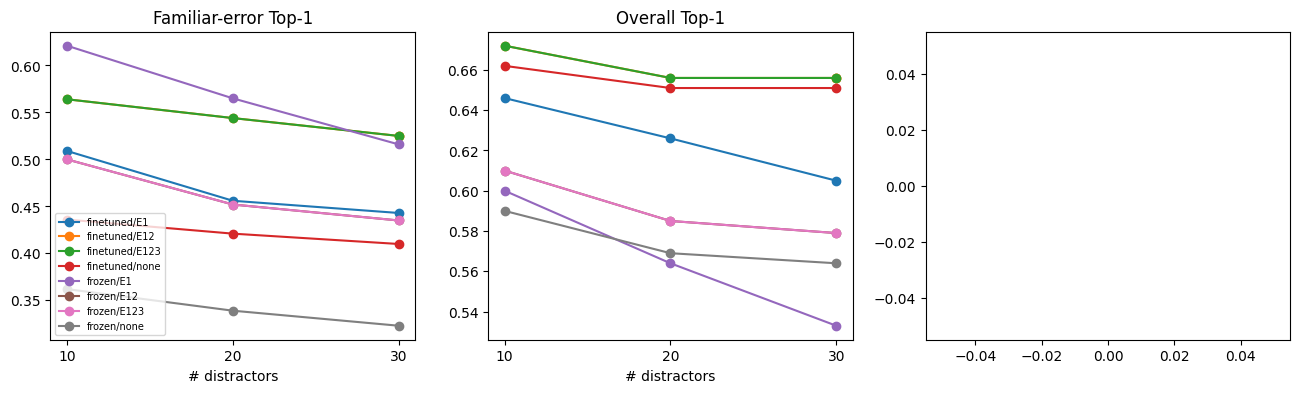

In [ ]:
import pandas as pd, matplotlib.pyplot as plt
from google.colab import files

TAU_F = 0.85   # E3: filter a tool if it failed on a query this similar

def attempt2(Q, T, idx, cands, qi, mem, lam, tau, mode, R=3):
    sc = Q[qi] @ T[[idx[c] for c in cands]].T
    tried, picks = set(), []
    for a in range(1, R + 1):
        s2 = sc.clone()
        for j, c in enumerate(cands):
            if j in tried: s2[j] = -9; continue
            if mode != "none" and c in mem:
                sims = torch.stack(mem[c]) @ Q[qi]
                if mode == "E1":
                    s2[j] -= lam
                else:
                    p = sims.max().item()
                    if p >= tau: s2[j] -= lam * p
                    if mode == "E123" and p >= TAU_F: s2[j] = -9
        j = int(s2.argmax()); picks.append(j)
        if j == 0: return a, picks
        tried.add(j)
    return None, picks

encoders = {"frozen": base, "finetuned": model}
rows = []
for ename, enc in encoders.items():
    for k in (10, 20, 30):
        for mode in ("none", "E1", "E12", "E123"):
            t1, f1, at = run_fam2(enc, "test", k, LAM2, TAU2, mode)
            rows.append(dict(encoder=ename, distractors=k, mode=mode, pollution=0.0,
                             top1=t1, fam_top1=f1, avg_attempts=at))
# pollution test (fine-tuned encoder, E1+E2, +30), mean of 3 seeds
for p in (0.0, 0.2, 0.4, 0.6):
    r = np.mean([run_fam2(model, "test", 30, LAM2, TAU2, "E12", p, seed=s) for s in range(3)], axis=0)
    rows.append(dict(encoder="finetuned", distractors=30, mode="E12", pollution=p,
                     top1=r[0], fam_top1=r[1], avg_attempts=r[2]))

df = pd.DataFrame(rows).round(3)
df.to_csv("results.csv", index=False)
print(df[df.pollution == 0].pivot_table(index=["encoder", "mode"], columns="distractors",
                                         values="fam_top1"))

# ---- plots ----
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
d0 = df[df.pollution == 0]
for (e, m), g in d0.groupby(["encoder", "mode"]):
    ax[0].plot(g.distractors, g.fam_top1, marker="o", label=f"{e}/{m}")
    ax[1].plot(g.distractors, g.top1, marker="o", label=f"{e}/{m}")
ax[0].set_title("Familiar-error Top-1"); ax[1].set_title("Overall Top-1")
for a in ax[:2]: a.set_xlabel("# distractors"); a.set_xticks([10, 20, 30])
ax[0].legend(fontsize=7)
pg = df[df.pollution.isin([0.0, 0.2, 0.4, 0.6]) & (df.mode == "E12") & (df.distractors == 30) & (df.encoder == "finetuned")]
ax[2].plot(pg.pollution * 100, pg.top1, marker="o", label="overall Top-1")
ax[2].plot(pg.pollution * 100, pg.fam_top1, marker="o", label="familiar Top-1")
ax[2].axhline(d0[(d0.encoder == "finetuned") & (d0.mode == "none") & (d0.distractors == 30)].fam_top1.iloc[0],
              ls="--", c="gray", label="no-memory (familiar)")
ax[2].set_title("Memory pollution (+30)"); ax[2].set_xlabel("% corrupted memory"); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.savefig("results.png", dpi=150); plt.show()

files.download("results.csv"); files.download("results.png")

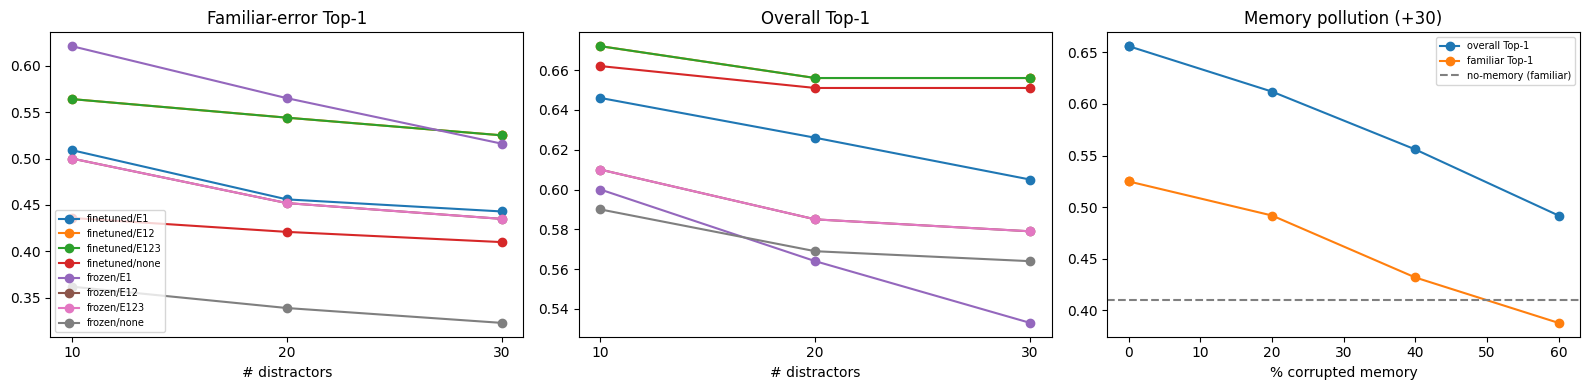

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
import matplotlib.pyplot as plt

d0 = df[df["pollution"] == 0]
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for (e, m), g in d0.groupby(["encoder", "mode"]):
    ax[0].plot(g["distractors"], g["fam_top1"], marker="o", label=f"{e}/{m}")
    ax[1].plot(g["distractors"], g["top1"], marker="o", label=f"{e}/{m}")
ax[0].set_title("Familiar-error Top-1"); ax[1].set_title("Overall Top-1")
for a in ax[:2]: a.set_xlabel("# distractors"); a.set_xticks([10, 20, 30])
ax[0].legend(fontsize=7)

pg = df[(df["mode"] == "E12") & (df["distractors"] == 30) & (df["encoder"] == "finetuned")]
ax[2].plot(pg["pollution"] * 100, pg["top1"], marker="o", label="overall Top-1")
ax[2].plot(pg["pollution"] * 100, pg["fam_top1"], marker="o", label="familiar Top-1")
nm = d0[(d0["encoder"] == "finetuned") & (d0["mode"] == "none") & (d0["distractors"] == 30)]["fam_top1"].iloc[0]
ax[2].axhline(nm, ls="--", c="gray", label="no-memory (familiar)")
ax[2].set_title("Memory pollution (+30)"); ax[2].set_xlabel("% corrupted memory"); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.savefig("results.png", dpi=150); plt.show()

df.to_csv("results.csv", index=False)
files.download("results.csv"); files.download("results.png")

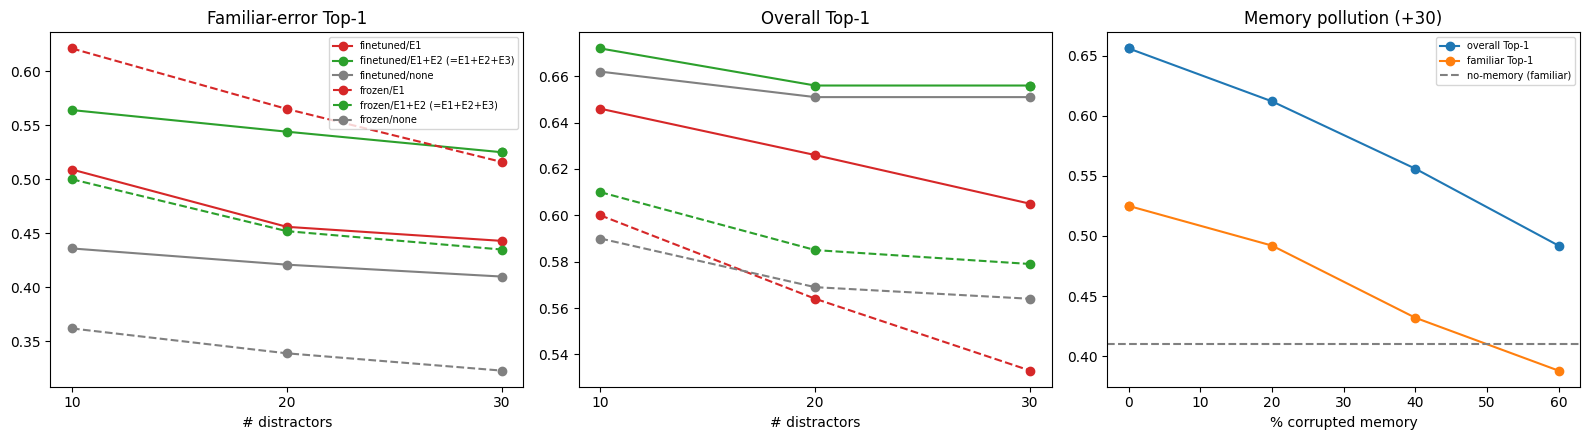

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
colors = {"none": "gray", "E1": "tab:red", "E12": "tab:green", "E123": "tab:blue"}
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for (e, m), g in d0.groupby(["encoder", "mode"]):
    if m == "E123": continue   # identical to E12, so mention it in the caption
    ls = "-" if e == "finetuned" else "--"
    lab = "E1+E2 (=E1+E2+E3)" if m == "E12" else m
    ax[0].plot(g["distractors"], g["fam_top1"], ls, marker="o", c=colors[m], label=f"{e}/{lab}")
    ax[1].plot(g["distractors"], g["top1"], ls, marker="o", c=colors[m])
ax[0].set_title("Familiar-error Top-1"); ax[1].set_title("Overall Top-1")
for a in ax[:2]: a.set_xlabel("# distractors"); a.set_xticks([10, 20, 30])
ax[0].legend(fontsize=7)
ax[2].plot(pg["pollution"]*100, pg["top1"], marker="o", label="overall Top-1")
ax[2].plot(pg["pollution"]*100, pg["fam_top1"], marker="o", label="familiar Top-1")
ax[2].axhline(nm, ls="--", c="gray", label="no-memory (familiar)")
ax[2].set_title("Memory pollution (+30)"); ax[2].set_xlabel("% corrupted memory"); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.savefig("results.png", dpi=150); plt.show()
files.download("results.png")

In [ ]:
# 1. Install Groq
!pip install -q groq

import time
from google.colab import userdata
from groq import Groq

# 2. Initialize the Groq client
api_key = userdata.get('GROQ_API_KEY')
client = Groq(api_key=api_key)

def llm_select_tool(query, tool_shortlist, max_retries=5):
    """Passes the query to Groq's GPT-OSS 20B with a retry loop."""

    prompt = f"""You are an API router. Match the user query to the exact correct tool.

User Query: {query}

Available Tools:
"""
    for i, tool in enumerate(tool_shortlist):
        prompt += f"{i+1}. {tool}\n"

    prompt += "\nRespond ONLY with the exact name of the tool (e.g., 'send_money_api'). Do not include explanations."

    for attempt in range(max_retries):
        try:
            # We use OpenAI's 20B open-weight model with its 250k TPM free limit!
            response = client.chat.completions.create(
                model="openai/gpt-oss-20b",
                messages=[
                    {"role": "user", "content": prompt}
                ],
                temperature=0.0 # Keep it strict so it doesn't hallucinate API names
            )
            return response.choices[0].message.content.strip()

        except Exception as e:
            if "429" in str(e) or "503" in str(e):
                wait_time = 3 * (attempt + 1)
                print(f"⚠️ Rate limit hit. Retrying in {wait_time}s... (Attempt {attempt + 1}/{max_retries})")
                time.sleep(wait_time)
            else:
                raise e

    return "API_ERROR: FAILED_AFTER_RETRIES"

# 3. Test it!
test_query = "Check if my $50 transfer to Sarah went through."
retriever_shortlist = [
    "send_money_api: Transfers funds to a recipient account.",
    "request_money_api: Sends a payment request to another user.",
    "check_transfer_api: Checks the status of a past money transfer."
]

print("Sending shortlist to Groq...")
final_choice = llm_select_tool(test_query, retriever_shortlist)

print(f"\nUser Query: {test_query}")
print(f"Groq's Final Selection: {final_choice}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 143.8/143.8 kB 4.6 MB/s eta 0:00:00
Sending shortlist to Groq...

User Query: Check if my $50 transfer to Sarah went through.
Groq's Final Selection: check_transfer_api


In [ ]:
import time
import numpy as np
from sentence_transformers import SentenceTransformer, util
from google.colab import userdata
from groq import Groq

# --- 1. INITIALIZATION ---
print("Loading Models...")
retriever_model = SentenceTransformer('all-MiniLM-L6-v2')
groq_client = Groq(api_key=userdata.get('GROQ_API_KEY'))

# --- 2. EXPERIMENT PARAMETERS (From Section 3.2 of your paper) ---
tau = 0.5       # Similarity threshold (τ)
lam = 0.3       # Penalty weight (λ)
max_retries = 3 # Maximum retries (R=3)
distractor_levels = [0, 10, 20, 30]

# --- 3. DUMMY DATASET GENERATOR ---
# We simulate your controlled benchmark here. You can swap this for a CSV later!
test_query = "Transfer $100 to my brother Mike"
correct_tool = "send_money_api: Transfers funds to a recipient account."

# Generate 30 highly similar distractors to stress-test the system
all_distractors = [
    f"transfer_funds_v{i}_api: Initiates a transfer of $100 to a family member."
    for i in range(1, 31)
]

# --- 4. CORE FUNCTIONS ---
def get_llm_selection(query, shortlist):
    """Calls Groq to pick the best tool from the retriever's shortlist."""
    prompt = f"User Query: {query}\n\nAvailable Tools:\n" + "\n".join([f"{i+1}. {t}" for i, t in enumerate(shortlist)]) + "\n\nRespond ONLY with the exact name of the tool (e.g., 'send_money_api')."

    for attempt in range(3):
        try:
            resp = groq_client.chat.completions.create(
                model="openai/gpt-oss-20b",
                messages=[{"role": "user", "content": prompt}],
                temperature=0.0
            )
            return resp.choices[0].message.content.strip()
        except Exception as e:
            time.sleep(2)
    return "API_ERROR"

# --- 5. THE MAIN EXPERIMENT LOOP (Section 5 Ablation Study) ---
print("\n=== STARTING DISTRACTOR STRESS TEST ===")

for num_distractors in distractor_levels:
    print(f"\n--- Testing with {num_distractors} Distractors ---")

    # 1. Build the tool library for this level
    current_tools = [correct_tool] + all_distractors[:num_distractors]

    # 2. Base Retrieval (Baseline)
    q_vec = retriever_model.encode(test_query)
    t_vecs = retriever_model.encode(current_tools)
    base_scores = util.cos_sim(q_vec, t_vecs)[0].tolist()

    # Get Top-3 Shortlist
    top_3_indices = np.argsort(base_scores)[-3:][::-1]
    shortlist = [current_tools[i] for i in top_3_indices]

    # LLM Selection (Baseline - Attempt 1)
    baseline_choice = get_llm_selection(test_query, shortlist)

    if baseline_choice.split(":")[0] == correct_tool.split(":")[0]:
        print(f"✅ Baseline SUCCESS! Picked correct tool on first try.")
        continue # Move to next distractor level

    print(f"❌ Baseline FAILED. Picked distractor: {baseline_choice}")

    # 3. APPLY EXPERIENCE MEMORY (Recovery Loop)
    experience_memory = [(test_query, baseline_choice)] # Save the failure
    print("   -> Stored failure in Experience Memory M.")

    recovered = False
    for retry in range(1, max_retries + 1):
        # Calculate Penalties: s'(q,t) = s(q,t) - λ * π(q,t)
        updated_scores = []
        for i, tool in enumerate(current_tools):
            s_qt = base_scores[i]
            pi_qt = 0.0

            # Check memory for this tool
            for failed_query, failed_tool in experience_memory:
                if failed_tool in tool: # If this tool failed before
                    sim = util.cos_sim(q_vec, retriever_model.encode(failed_query)).item()
                    if sim >= tau:
                        pi_qt = max(pi_qt, sim)

            s_prime = s_qt - (lam * pi_qt)
            updated_scores.append(s_prime)

        # Get New Top-3 Shortlist based on Penalized Scores
        new_top_3_indices = np.argsort(updated_scores)[-3:][::-1]
        new_shortlist = [current_tools[i] for i in new_top_3_indices]

        # LLM Selection (Attempt 2)
        memory_choice = get_llm_selection(test_query, new_shortlist)

        if memory_choice.split(":")[0] == correct_tool.split(":")[0]:
            print(f"✅ Recovery SUCCESS on Retry {retry}! Memory successfully penalized the distractor.")
            recovered = True
            break
        else:
            print(f"❌ Retry {retry} FAILED. Picked: {memory_choice}")
            experience_memory.append((test_query, memory_choice)) # Save new failure

    if not recovered:
        print("🚨 Final Failure: Could not recover within R=3 retries.")

Loading Models...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]


=== STARTING DISTRACTOR STRESS TEST ===

--- Testing with 0 Distractors ---
✅ Baseline SUCCESS! Picked correct tool on first try.

--- Testing with 10 Distractors ---
❌ Baseline FAILED. Picked distractor: transfer_funds_v10_api
   -> Stored failure in Experience Memory M.
❌ Retry 1 FAILED. Picked: transfer_funds_v8_api
❌ Retry 2 FAILED. Picked: transfer_funds_v7_api
❌ Retry 3 FAILED. Picked: transfer_funds_v9_api
🚨 Final Failure: Could not recover within R=3 retries.

--- Testing with 20 Distractors ---
❌ Baseline FAILED. Picked distractor: transfer_funds_v14_api
   -> Stored failure in Experience Memory M.
❌ Retry 1 FAILED. Picked: transfer_funds_v12_api
❌ Retry 2 FAILED. Picked: transfer_funds_v13_api
❌ Retry 3 FAILED. Picked: transfer_funds_v15_api
🚨 Final Failure: Could not recover within R=3 retries.

--- Testing with 30 Distractors ---
❌ Baseline FAILED. Picked distractor: transfer_funds_v27_api
   -> Stored failure in Experience Memory M.
❌ Retry 1 FAILED. Picked: transfer_fund

In [ ]:
!pip install -q groq
import time
from google.colab import userdata
from groq import Groq

groq_client = Groq(api_key=userdata.get('GROQ_API_KEY'))

In [ ]:
!pip install -q groq
import time
from google.colab import userdata
from groq import Groq

groq_client = Groq(api_key=userdata.get('GROQ_API_KEY'))

t0 = time.time()
for i in range(10):
    groq_client.chat.completions.create(
        model="openai/gpt-oss-20b",
        messages=[{"role": "user", "content": "Reply with the number 1."}], temperature=0.0)
dt = (time.time() - t0) / 10
print(f"{dt:.2f} s per call -> ~{700*dt/60:.0f} min for the big cell")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 143.8/143.8 kB 5.5 MB/s eta 0:00:00
0.27 s per call -> ~3 min for the big cell


In [ ]:
print([n for n in ("model", "tools", "splits", "pool", "neighbors") if n not in globals()])

['model', 'tools', 'splits', 'pool', 'neighbors']


In [ ]:
!pip install -q sentence-transformers datasets
!test -d ToolAlpaca || git clone -q https://github.com/tangqiaoyu/ToolAlpaca.git

import json, random, torch
from sentence_transformers import (SentenceTransformer, SentenceTransformerTrainer,
                                   SentenceTransformerTrainingArguments, losses)
from sentence_transformers.training_args import BatchSamplers
from datasets import Dataset
print("GPU:", torch.cuda.is_available())

# ---- tools + queries ----
d = json.load(open("/content/ToolAlpaca/data/train_data.json"))
tools = {}
for api in d:
    for fname, desc in api["Function_Description"].items():
        short = desc.split("\nParameters:")[0].strip()
        tools[f'{api["Name"]}::{fname}'] = f"{fname}: {short}"
data = []
for api in d:
    for inst in api["Instances"]:
        try: used = {step[0][0] for step in inst["intermediate_steps"]}
        except Exception: used = set()
        if len(used) != 1: continue
        tid = f'{api["Name"]}::{used.pop()}'
        if tid in tools:
            data.append({"query": inst["input"], "tool_id": tid, "api": api["Name"]})
print("tools:", len(tools), "| queries:", len(data))

# ---- splits + distractors + training ----
random.seed(42)
apis = sorted({x["api"] for x in data}); random.shuffle(apis)
n = len(apis); split_of = {}
for i, a in enumerate(apis):
    split_of[a] = "train" if i < 0.7*n else "val" if i < 0.85*n else "test"
splits = {s: [x for x in data if split_of[x["api"]] == s] for s in ("train","val","test")}
pool   = {s: [t for t in tools if split_of.get(t.split("::")[0]) == s] for s in splits}
print({s: (len(splits[s]), "queries", len(pool[s]), "tools") for s in splits})

base = SentenceTransformer("all-MiniLM-L6-v2", device="cuda")
def mine(split, k=30):
    ids = pool[split]
    emb = base.encode([tools[t] for t in ids], convert_to_tensor=True, normalize_embeddings=True, batch_size=128)
    sim = emb @ emb.T; sim.fill_diagonal_(-1)
    top = sim.topk(k, dim=1).indices.cpu().numpy()
    return {ids[i]: [ids[j] for j in top[i]] for i in range(len(ids))}
neighbors = {s: mine(s) for s in splits}

rows = {"anchor": [], "positive": [], "neg1": [], "neg2": [], "neg3": []}
for x in splits["train"]:
    negs = random.sample(neighbors["train"][x["tool_id"]][:10], 3)
    rows["anchor"].append(x["query"]); rows["positive"].append(tools[x["tool_id"]])
    for j, ng in enumerate(negs, 1): rows[f"neg{j}"].append(tools[ng])
train_ds = Dataset.from_dict(rows)

model = SentenceTransformer("all-MiniLM-L6-v2", device="cuda")
loss = losses.MultipleNegativesRankingLoss(model)
args = SentenceTransformerTrainingArguments(
    output_dir="enc_out", num_train_epochs=3, per_device_train_batch_size=32,
    learning_rate=2e-5, warmup_ratio=0.1, fp16=True,
    batch_sampler=BatchSamplers.NO_DUPLICATES,
    logging_steps=20, save_strategy="no", report_to="none")
SentenceTransformerTrainer(model=model, args=args, train_dataset=train_ds, loss=loss).train()
print("DONE - model, tools, splits, pool, neighbors are ready")

/tmp/ipykernel_471/2393541860.py:5: DeprecationWarning: Importing from 'sentence_transformers.losses' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.losses' instead.
  from sentence_transformers import (SentenceTransformer, SentenceTransformerTrainer,
/tmp/ipykernel_471/2393541860.py:7: DeprecationWarning: Importing from 'sentence_transformers.training_args' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.training_args' instead.
  from sentence_transformers.training_args import BatchSamplers


GPU: True
tools: 2695 | queries: 2643
{'train': (1874, 'queries', 1599, 'tools'), 'val': (375, 'queries', 330, 'tools'), 'test': (394, 'queries', 334, 'tools')}


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

... (9 outputs left out)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

Step,Training Loss
20,1.007378
40,0.674428
60,0.665860
80,0.507928
100,0.509473
120,0.450669
140,0.414003
160,0.377534


DONE - model, tools, splits, pool, neighbors are ready


In [ ]:
import time, re, torch, pandas as pd
from tqdm.auto import tqdm

LAM_USE, TAU_USE = 0.3, 0.6
LLM_CACHE = {}

def llm_pick(query, shortlist, max_retries=5):
    key = (query, tuple(shortlist))
    if key in LLM_CACHE: return LLM_CACHE[key]
    prompt = f"User Query: {query}\n\nAvailable Tools:\n"
    prompt += "\n".join(f"{i+1}. {t}" for i, t in enumerate(shortlist))
    prompt += "\n\nWhich tool should be used? Respond ONLY with the number of the tool."
    for n in range(max_retries):
        try:
            r = groq_client.chat.completions.create(
                model="openai/gpt-oss-20b",
                messages=[{"role": "user", "content": prompt}], temperature=0.0)
            txt = (r.choices[0].message.content or "").strip()
            m = re.search(r"\d+", txt)
            if m and 1 <= int(m.group()) <= len(shortlist):
                LLM_CACHE[key] = int(m.group()) - 1
                return LLM_CACHE[key]
            return None
        except Exception:
            time.sleep(3 * (n + 1))
    return None

def attempt_llm(Q, T, idx, cands, qi, qtext, mem, lam, tau, R=3, K=5):
    sc = Q[qi] @ T[[idx[c] for c in cands]].T
    tried, picks = set(), []
    for a in range(1, R + 1):
        s2 = sc.clone()
        for j, c in enumerate(cands):
            if j in tried: s2[j] = -9; continue
            if lam > 0 and c in mem:
                p = (torch.stack(mem[c]) @ Q[qi]).max().item()
                if p >= tau: s2[j] -= lam * p
        top = s2.topk(min(K, len(cands))).indices.tolist()
        choice = llm_pick(qtext, [tools[cands[i]] for i in top])
        if choice is None: return None, picks, True
        j = top[choice]; picks.append(j)
        if j == 0: return a, picks, False
        tried.add(j)
    return None, picks, False

def run_llm_eval(m, split, k, lam, tau, modes=("none", "E12"), R=3):
    qs, ids = splits[split], pool[split]
    idx = {t: i for i, t in enumerate(ids)}
    Q = m.encode([x["query"] for x in qs], convert_to_tensor=True, normalize_embeddings=True, batch_size=128)
    T = m.encode([tools[i] for i in ids], convert_to_tensor=True, normalize_embeddings=True, batch_size=128)
    byt = {}
    for i, x in enumerate(qs): byt.setdefault(x["tool_id"], []).append(i)
    multi = {t: v for t, v in byt.items() if len(v) >= 2}
    cands_of = lambda t: [t] + neighbors[split][t][:k]

    mem, failed = {}, {}
    for t, v in tqdm(multi.items(), desc="phase 1 (memory)"):
        cands = cands_of(t)
        a, picks, err = attempt_llm(Q, T, idx, cands, v[0], qs[v[0]]["query"], {}, 0, 0, R)
        if err or not picks: failed[t] = None; continue
        failed[t] = picks[0] != 0
        for j in picks:
            if j != 0: mem.setdefault(cands[j], []).append(Q[v[0]])

    results = []
    for mode in modes:
        L = lam if mode == "E12" else 0
        n = ok1 = okR = att = fn = fok1 = fokR = errs = 0
        for t, v in tqdm(multi.items(), desc=f"phase 2 ({mode})"):
            if failed[t] is None: continue
            cands = cands_of(t)
            for qi in v[1:]:
                a, picks, err = attempt_llm(Q, T, idx, cands, qi, qs[qi]["query"],
                                            mem if L > 0 else {}, L, tau, R)
                if err: errs += 1; continue
                n += 1; ok1 += picks[0] == 0; okR += a is not None; att += (a if a else R)
                if failed[t]:
                    fn += 1; fok1 += picks[0] == 0; fokR += a is not None
        results.append(dict(mode=mode, distractors=k, n=n, top1=ok1/n, succ_R=okR/n,
                            avg_attempts=att/n, fam_n=fn, fam_top1=fok1/max(fn, 1),
                            fam_succ_R=fokR/max(fn, 1), api_errors=errs))
    return pd.DataFrame(results).round(3)

llm_df = run_llm_eval(model, "test", 30, LAM_USE, TAU_USE)
print(llm_df.to_string(index=False))
llm_df.to_csv("llm_results.csv", index=False)

phase 1 (memory):   0%|          | 0/107 [00:00<?, ?it/s]

phase 2 (none):   0%|          | 0/107 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
!pip install -q groq
import time, re, os, pickle, torch, pandas as pd
from tqdm.auto import tqdm
from google.colab import drive, userdata
from groq import Groq

drive.mount('/content/drive')
CACHE_PATH = "/content/drive/MyDrive/llm_cache.pkl"
LLM_CACHE = pickle.load(open(CACHE_PATH, "rb")) if os.path.exists(CACHE_PATH) else {}
print("cache entries loaded:", len(LLM_CACHE))
groq_client = Groq(api_key=userdata.get('GROQ_API_KEY'))

LAM_USE, TAU_USE, MAX_TOOLS = 0.3, 0.6, 107
_new = 0
def save_cache():
    pickle.dump(LLM_CACHE, open(CACHE_PATH, "wb"))

def llm_pick(query, shortlist, max_retries=5):
    global _new
    key = (query, tuple(shortlist))
    if key in LLM_CACHE: return LLM_CACHE[key]
    prompt = f"User Query: {query}\n\nAvailable Tools:\n"
    prompt += "\n".join(f"{i+1}. {t}" for i, t in enumerate(shortlist))
    prompt += "\n\nWhich tool should be used? Respond ONLY with the number of the tool."
    for n in range(max_retries):
        try:
            r = groq_client.chat.completions.create(
                model="openai/gpt-oss-20b",
                messages=[{"role": "user", "content": prompt}], temperature=0.0)
            m = re.search(r"\d+", (r.choices[0].message.content or ""))
            if m and 1 <= int(m.group()) <= len(shortlist):
                LLM_CACHE[key] = int(m.group()) - 1
                _new += 1
                if _new % 10 == 0: save_cache()
                return LLM_CACHE[key]
            return None
        except Exception as e:
            if "429" in str(e) or "503" in str(e): time.sleep(3 * (n + 1))
            else: return None
    return None

def attempt_llm(Q, T, idx, cands, qi, qtext, mem, lam, tau, R=3, K=5):
    sc = Q[qi] @ T[[idx[c] for c in cands]].T
    tried, picks = set(), []
    for a in range(1, R + 1):
        s2 = sc.clone()
        for j, c in enumerate(cands):
            if j in tried: s2[j] = -9; continue
            if lam > 0 and c in mem:
                p = (torch.stack(mem[c]) @ Q[qi]).max().item()
                if p >= tau: s2[j] -= lam * p
        top = s2.topk(min(K, len(cands))).indices.tolist()
        choice = llm_pick(qtext, [tools[cands[i]] for i in top])
        if choice is None: return None, picks, True
        j = top[choice]; picks.append(j)
        if j == 0: return a, picks, False
        tried.add(j)
    return None, picks, False

def run_llm_eval(m, split, k, lam, tau, modes=("none", "E12"), R=3):
    qs, ids = splits[split], pool[split]
    idx = {t: i for i, t in enumerate(ids)}
    Q = m.encode([x["query"] for x in qs], convert_to_tensor=True, normalize_embeddings=True, batch_size=128)
    T = m.encode([tools[i] for i in ids], convert_to_tensor=True, normalize_embeddings=True, batch_size=128)
    byt = {}
    for i, x in enumerate(qs): byt.setdefault(x["tool_id"], []).append(i)
    multi = {t: v for t, v in byt.items() if len(v) >= 2}
    multi = dict(list(multi.items())[:MAX_TOOLS])
    cands_of = lambda t: [t] + neighbors[split][t][:k]

    mem, failed = {}, {}
    for t, v in tqdm(multi.items(), desc="phase 1 (memory)"):
        cands = cands_of(t)
        a, picks, err = attempt_llm(Q, T, idx, cands, v[0], qs[v[0]]["query"], {}, 0, 0, R)
        if err or not picks: failed[t] = None; continue
        failed[t] = picks[0] != 0
        for j in picks:
            if j != 0: mem.setdefault(cands[j], []).append(Q[v[0]])

    results = []
    for mode in modes:
        L = lam if mode == "E12" else 0
        n = ok1 = okR = att = fn = fok1 = fokR = errs = 0
        for t, v in tqdm(multi.items(), desc=f"phase 2 ({mode})"):
            if failed[t] is None: continue
            cands = cands_of(t)
            for qi in v[1:]:
                a, picks, err = attempt_llm(Q, T, idx, cands, qi, qs[qi]["query"],
                                            mem if L > 0 else {}, L, tau, R)
                if err: errs += 1; continue
                n += 1; ok1 += picks[0] == 0; okR += a is not None; att += (a if a else R)
                if failed[t]:
                    fn += 1; fok1 += picks[0] == 0; fokR += a is not None
        results.append(dict(mode=mode, distractors=k, n=n, top1=ok1/n, succ_R=okR/n,
                            avg_attempts=att/n, fam_n=fn, fam_top1=fok1/max(fn, 1),
                            fam_succ_R=fokR/max(fn, 1), api_errors=errs))
    save_cache()
    return pd.DataFrame(results).round(3)

llm_df = run_llm_eval(model, "test", 30, LAM_USE, TAU_USE)
print(llm_df.to_string(index=False))
llm_df.to_csv("/content/drive/MyDrive/llm_results.csv", index=False)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
cache entries loaded: 78


phase 1 (memory):   0%|          | 0/107 [00:00<?, ?it/s]

phase 2 (none):   0%|          | 0/107 [00:00<?, ?it/s]

phase 2 (E12):   0%|          | 0/107 [00:00<?, ?it/s]

mode  distractors   n  top1  succ_R  avg_attempts  fam_n  fam_top1  fam_succ_R  api_errors
none           30 180 0.811   0.972         1.233     34     0.500         1.0          11
 E12           30 179 0.816   0.972         1.229     34     0.529         1.0          12


In [ ]:
# ============================================================
# PAIRED STATS + MULTI-SPLIT CELL  (cosine selector, fine-tuned encoder)
# Paste into a NEW cell AFTER the cell that defines: data, tools, base
# (that's the "splits + distractors + training" cell, exec=3 in your notebook).
# It does NOT touch your existing globals (splits/pool/neighbors/model);
# everything lives in the world dict W built per split seed.
# Needs GPU. Roughly 3-5 min per split seed on a T4 (mostly encoder training).
# ============================================================
import random, pickle
import numpy as np
import torch
from datasets import Dataset
from sentence_transformers import (SentenceTransformer, SentenceTransformerTrainer,
                                   SentenceTransformerTrainingArguments, losses)
from sentence_transformers.training_args import BatchSamplers
from statsmodels.stats.contingency_tables import mcnemar

SEEDS = [42, 1, 2, 3, 4]      # 42 = your current split, should reproduce your tables
KS    = (10, 20, 30)
MODES = ("none", "E1", "E12")  # none = retry-only baseline (hard-excludes tried tools)


# ---------- build one full world (split + distractors + fine-tuned encoder) ----------
def build_world(seed):
    rnd = random.Random(seed)
    apis = sorted({x["api"] for x in data}); rnd.shuffle(apis)
    n = len(apis); split_of = {}
    for i, a in enumerate(apis):
        split_of[a] = "train" if i < 0.7 * n else "val" if i < 0.85 * n else "test"
    sp = {s: [x for x in data if split_of[x["api"]] == s] for s in ("train", "val", "test")}
    pl = {s: [t for t in tools if split_of.get(t.split("::")[0]) == s] for s in sp}

    def mine(split, k=30):
        ids = pl[split]
        emb = base.encode([tools[t] for t in ids], convert_to_tensor=True,
                          normalize_embeddings=True, batch_size=128)
        sim = emb @ emb.T; sim.fill_diagonal_(-1)
        top = sim.topk(k, dim=1).indices.cpu().numpy()
        return {ids[i]: [ids[j] for j in top[i]] for i in range(len(ids))}
    nb = {s: mine(s) for s in sp}

    rows = {"anchor": [], "positive": [], "neg1": [], "neg2": [], "neg3": []}
    for x in sp["train"]:
        negs = rnd.sample(nb["train"][x["tool_id"]][:10], 3)
        rows["anchor"].append(x["query"]); rows["positive"].append(tools[x["tool_id"]])
        for j, ng in enumerate(negs, 1): rows[f"neg{j}"].append(tools[ng])
    train_ds = Dataset.from_dict(rows)

    mdl = SentenceTransformer("all-MiniLM-L6-v2", device="cuda")
    args = SentenceTransformerTrainingArguments(
        output_dir="enc_out_pq", num_train_epochs=3, per_device_train_batch_size=32,
        learning_rate=2e-5, warmup_ratio=0.1, fp16=True, seed=seed,
        batch_sampler=BatchSamplers.NO_DUPLICATES,
        logging_steps=50, save_strategy="no", report_to="none")
    SentenceTransformerTrainer(model=mdl, args=args, train_dataset=train_ds,
                               loss=losses.MultipleNegativesRankingLoss(mdl)).train()

    emb = {}
    for s in ("val", "test"):
        Q = mdl.encode([x["query"] for x in sp[s]], convert_to_tensor=True,
                       normalize_embeddings=True, batch_size=128)
        T = mdl.encode([tools[i] for i in pl[s]], convert_to_tensor=True,
                       normalize_embeddings=True, batch_size=128)
        emb[s] = (Q, T)
    return dict(splits=sp, pool=pl, neighbors=nb, emb=emb)


# ---------- one query attempt (hard-excludes tried tools; same logic as your attempt2) ----------
def attempt_pq(Q, T, idx, cands, qi, mem, lam, tau, mode, R=3):
    sc = Q[qi] @ T[[idx[c] for c in cands]].T
    tried, picks = set(), []
    for a in range(1, R + 1):
        s2 = sc.clone()
        for j, c in enumerate(cands):
            if j in tried: s2[j] = -9; continue
            if mode != "none" and c in mem:
                sims = torch.stack(mem[c]) @ Q[qi]
                if mode == "E1":
                    s2[j] -= lam                     # flat penalty
                else:                                # E12: similarity-weighted
                    p = sims.max().item()
                    if p >= tau: s2[j] -= lam * p
        j = int(s2.argmax()); picks.append(j)
        if j == 0: return a, picks
        tried.add(j)
    return None, picks


# ---------- your phase-1 / phase-2 protocol, but returns ONE ROW PER TEST QUERY ----------
# row = (tool_id, query_idx, familiar_error_flag, first_attempt_correct, success_within_R, attempts)
def run_pq(W, split, k, lam, tau, mode, R=3):
    qs, ids = W["splits"][split], W["pool"][split]
    Q, T = W["emb"][split]
    idx = {t: i for i, t in enumerate(ids)}
    byt = {}
    for i, x in enumerate(qs): byt.setdefault(x["tool_id"], []).append(i)
    multi = {t: v for t, v in byt.items() if len(v) >= 2}
    cands_of = lambda t: [t] + W["neighbors"][split][t][:k]

    mem, failed = {}, {}
    for t, v in multi.items():                       # phase 1: build memory from 1st query per tool
        cands = cands_of(t)
        a, picks = attempt_pq(Q, T, idx, cands, v[0], {}, 0, 0, "none", R)
        failed[t] = picks[0] != 0
        for j in picks:
            if j != 0: mem.setdefault(cands[j], []).append(Q[v[0]])

    rows = []
    for t, v in multi.items():                       # phase 2: test queries, memory frozen
        cands = cands_of(t)
        for qi in v[1:]:
            a, picks = attempt_pq(Q, T, idx, cands, qi, mem if mode != "none" else {},
                                  lam, tau, mode, R)
            rows.append((t, qi, bool(failed[t]), picks[0] == 0, a is not None, a if a else R))
    return rows


# ---------- val sweep (cosine selector) so lambda/tau have a reproducible origin ----------
def sweep(W, k=30):
    best = None
    for lam in (0.1, 0.3, 0.5):
        for tau in (0.6, 0.7, 0.8):
            rows = run_pq(W, "val", k, lam, tau, "E12")
            fam = [r for r in rows if r[2]]
            f1 = float(np.mean([r[3] for r in fam])) if fam else 0.0
            o1 = float(np.mean([r[3] for r in rows]))
            print(f"lam={lam} tau={tau} | val fam_top1={f1:.3f} (n={len(fam)}) | overall top1={o1:.3f}")
            if best is None or (f1, o1) > best[0]: best = ((f1, o1), lam, tau)
    print("BEST on val ->", best)
    return best


# ---------- paired tests ----------
def cluster_boot(keys, d, n_boot=10000, seed=0):
    """95% CI on mean paired difference, resampling TOOLS (queries of one tool are correlated)."""
    rng = np.random.default_rng(seed)
    _, inv = np.unique(keys, return_inverse=True)
    sums = np.bincount(inv, weights=d); cnt = np.bincount(inv)
    G = len(sums); out = np.empty(n_boot)
    for b in range(n_boot):
        pick = rng.integers(0, G, G)
        out[b] = sums[pick].sum() / cnt[pick].sum()
    return np.percentile(out, [2.5, 97.5])

def paired(rows_a, rows_b, col, mask, label):
    assert all(x[:3] == y[:3] for x, y in zip(rows_a, rows_b)), "rows not aligned"
    a = np.array([r[col] for r in rows_a], float)[mask]
    b = np.array([r[col] for r in rows_b], float)[mask]
    keys = np.array([f"{r[0]}|{r[1]}" for r in rows_a])[mask]   # cluster = (split seed | tool)
    helped = int(((a == 0) & (b == 1)).sum()); hurt = int(((a == 1) & (b == 0)).sum())
    both = int(((a == 1) & (b == 1)).sum());   neither = int(((a == 0) & (b == 0)).sum())
    p = mcnemar([[both, hurt], [helped, neither]], exact=True).pvalue
    lo, hi = cluster_boot(keys, b - a)
    print(f"  {label:<28} n={len(a):4d} | {a.mean():.3f} -> {b.mean():.3f} "
          f"(diff {b.mean()-a.mean():+.3f}, cluster 95% CI [{lo:+.3f}, {hi:+.3f}]) "
          f"| helped={helped} hurt={hurt} | McNemar p={p:.4f}")


# ============================ RUN ============================
W42 = build_world(42)
print("=== val sweep on the seed-42 split ===")
sweep(W42)
LAM, TAU = 0.3, 0.6      # <- change these if the sweep above picks something else

res = {}                 # (k, mode) -> rows tagged with split seed
for sd in SEEDS:
    W = W42 if sd == 42 else build_world(sd)
    for k in KS:
        for mode in MODES:
            res.setdefault((k, mode), []).extend((sd,) + r for r in run_pq(W, "test", k, LAM, TAU, mode))
    if sd != 42:
        del W; torch.cuda.empty_cache()
pickle.dump(res, open("paired_rows.pkl", "wb"))

# row layout after tagging: 0 seed, 1 tool, 2 qi, 3 familiar, 4 first_ok, 5 success_in_R, 6 attempts
print("\n=== PER-SPLIT familiar-error Top-1 (+30)  [seed 42 should match your table: 0.410 / 0.525] ===")
for sd in SEEDS:
    line = f"seed {sd}: "
    for mode in MODES:
        r = [x for x in res[(30, mode)] if x[0] == sd and x[3]]
        line += f"{mode}={np.mean([x[4] for x in r]):.3f} (n={len(r)})  "
    ov = [x for x in res[(30, 'E12')] if x[0] == sd]; ov0 = [x for x in res[(30, 'none')] if x[0] == sd]
    line += f"| overall none={np.mean([x[4] for x in ov0]):.3f} E12={np.mean([x[4] for x in ov]):.3f}"
    print(line)

print("\n=== POOLED PAIRED TESTS (all splits; baseline = none) ===")
for k in KS:
    base_rows = res[(k, "none")]
    fam  = np.array([r[3] for r in base_rows], bool)
    allq = np.ones(len(base_rows), bool)
    print(f"\n+{k} distractors")
    for mode in ("E1", "E12"):
        paired(base_rows, res[(k, mode)], 4, fam,  f"{mode} familiar Top-1")
        paired(base_rows, res[(k, mode)], 4, allq, f"{mode} overall Top-1")
    # replaces your section 5.5 comparison: both arms hard-exclude tried tools here
    paired(base_rows, res[(k, "E12")], 5, allq, "E12 success within R=3")
    at0 = np.mean([r[6] for r in base_rows]); at1 = np.mean([r[6] for r in res[(k, "E12")]])
    print(f"  avg attempts: none={at0:.3f}  E12={at1:.3f}")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

Step,Training Loss
50,0.802916
100,0.543127
150,0.418714


=== val sweep on the seed-42 split ===
lam=0.1 tau=0.6 | val fam_top1=0.585 (n=41) | overall top1=0.786
lam=0.1 tau=0.7 | val fam_top1=0.561 (n=41) | overall top1=0.786
lam=0.1 tau=0.8 | val fam_top1=0.561 (n=41) | overall top1=0.786
lam=0.3 tau=0.6 | val fam_top1=0.610 (n=41) | overall top1=0.791
lam=0.3 tau=0.7 | val fam_top1=0.585 (n=41) | overall top1=0.791
lam=0.3 tau=0.8 | val fam_top1=0.561 (n=41) | overall top1=0.786
lam=0.5 tau=0.6 | val fam_top1=0.610 (n=41) | overall top1=0.786
lam=0.5 tau=0.7 | val fam_top1=0.585 (n=41) | overall top1=0.791
lam=0.5 tau=0.8 | val fam_top1=0.561 (n=41) | overall top1=0.786
BEST on val -> ((0.6097560975609756, 0.7912087912087912), 0.3, 0.6)


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

... (7 outputs left out)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

Step,Training Loss
50,0.894101
100,0.551749
150,0.472733



=== PER-SPLIT familiar-error Top-1 (+30)  [seed 42 should match your table: 0.410 / 0.525] ===
seed 42: none=0.397 (n=58)  E1=0.448 (n=58)  E12=0.534 (n=58)  | overall none=0.646 E12=0.656
seed 1: none=0.418 (n=79)  E1=0.582 (n=79)  E12=0.481 (n=79)  | overall none=0.653 E12=0.663
seed 2: none=0.588 (n=68)  E1=0.618 (n=68)  E12=0.691 (n=68)  | overall none=0.740 E12=0.755
seed 3: none=0.368 (n=87)  E1=0.529 (n=87)  E12=0.529 (n=87)  | overall none=0.614 E12=0.671
seed 4: none=0.378 (n=82)  E1=0.598 (n=82)  E12=0.537 (n=82)  | overall none=0.665 E12=0.708

=== POOLED PAIRED TESTS (all splits; baseline = none) ===

+10 distractors
  E1 familiar Top-1            n= 367 | 0.439 -> 0.602 (diff +0.163, cluster 95% CI [+0.082, +0.246]) | helped=86 hurt=26 | McNemar p=0.0000
  E1 overall Top-1             n=1023 | 0.674 -> 0.683 (diff +0.009, cluster 95% CI [-0.029, +0.046]) | helped=96 hurt=87 | McNemar p=0.5544
  E12 familiar Top-1           n= 367 | 0.439 -> 0.580 (diff +0.142, cluster 95%

In [ ]:
# Conservative re-check of the pooled results. NO retraining.
# Uses `res` from the previous cell (or loads paired_rows.pkl if the runtime restarted).
# Row layout: 0 seed, 1 tool, 2 qi, 3 familiar, 4 first_ok, 5 success_in_R, 6 attempts
import pickle
import numpy as np
from statsmodels.stats.contingency_tables import mcnemar

try:
    res
except NameError:
    res = pickle.load(open("paired_rows.pkl", "rb"))

def cluster_boot(keys, d, n_boot=10000, seed=0):
    rng = np.random.default_rng(seed)
    _, inv = np.unique(keys, return_inverse=True)
    sums = np.bincount(inv, weights=d); cnt = np.bincount(inv)
    G = len(sums); out = np.empty(n_boot)
    for b in range(n_boot):
        pick = rng.integers(0, G, G)
        out[b] = sums[pick].sum() / cnt[pick].sum()
    return np.percentile(out, [2.5, 97.5])

def paired2(rows_a, rows_b, col, mask, label):
    """Same as before, but cluster = TOOL ONLY, so a tool that shows up in the test sets
    of several splits counts as ONE cluster (more conservative than seed|tool)."""
    assert all(x[:3] == y[:3] for x, y in zip(rows_a, rows_b)), "rows not aligned"
    a = np.array([r[col] for r in rows_a], float)[mask]
    b = np.array([r[col] for r in rows_b], float)[mask]
    keys = np.array([r[1] for r in rows_a])[mask]
    helped = int(((a == 0) & (b == 1)).sum()); hurt = int(((a == 1) & (b == 0)).sum())
    both = int(((a == 1) & (b == 1)).sum());   neither = int(((a == 0) & (b == 0)).sum())
    p = mcnemar([[both, hurt], [helped, neither]], exact=True).pvalue
    lo, hi = cluster_boot(keys, b - a)
    print(f"  {label:<30} n={len(a):4d} | {a.mean():.3f} -> {b.mean():.3f} "
          f"(diff {b.mean()-a.mean():+.3f}, tool-cluster 95% CI [{lo:+.3f}, {hi:+.3f}]) "
          f"| helped={helped} hurt={hurt} | McNemar p={p:.4f}")

SEEDS = sorted({r[0] for r in res[(30, "none")]})
for k in (10, 20, 30):
    base_rows = res[(k, "none")]
    fam = np.array([r[3] for r in base_rows], bool)
    allq = np.ones(len(base_rows), bool)
    print(f"\n+{k} distractors")
    paired2(base_rows, res[(k, "E12")], 4, fam,  "E12 vs none | familiar")
    paired2(base_rows, res[(k, "E12")], 4, ~fam, "E12 vs none | NON-familiar")
    paired2(base_rows, res[(k, "E12")], 4, allq, "E12 vs none | overall")
    paired2(base_rows, res[(k, "E1")],  4, allq, "E1  vs none | overall")
    paired2(res[(k, "E1")], res[(k, "E12")], 4, allq, "E12 vs E1   | overall")
    paired2(res[(k, "E1")], res[(k, "E12")], 4, fam,  "E12 vs E1   | familiar")

    # spread across the 5 splits (the most conservative view: n = number of splits)
    seeds_arr = np.array([r[0] for r in base_rows])
    a = np.array([r[4] for r in base_rows], float)
    b = np.array([r[4] for r in res[(k, "E12")]], float)
    for nm, m in (("familiar", fam), ("overall", allq)):
        d = [b[(seeds_arr == s) & m].mean() - a[(seeds_arr == s) & m].mean() for s in SEEDS]
        print(f"  per-split E12-none diff, {nm:<8}: mean {np.mean(d):+.3f}, sd {np.std(d, ddof=1):.3f}, "
              f"positive in {sum(x > 0 for x in d)}/{len(d)} splits")


+10 distractors
  E12 vs none | familiar         n= 367 | 0.439 -> 0.580 (diff +0.142, tool-cluster 95% CI [+0.092, +0.200]) | helped=53 hurt=1 | McNemar p=0.0000
  E12 vs none | NON-familiar     n= 656 | 0.806 -> 0.782 (diff -0.024, tool-cluster 95% CI [-0.045, -0.008]) | helped=0 hurt=16 | McNemar p=0.0000
  E12 vs none | overall          n=1023 | 0.674 -> 0.710 (diff +0.035, tool-cluster 95% CI [+0.009, +0.063]) | helped=53 hurt=17 | McNemar p=0.0000
  E1  vs none | overall          n=1023 | 0.674 -> 0.683 (diff +0.009, tool-cluster 95% CI [-0.035, +0.051]) | helped=96 hurt=87 | McNemar p=0.5544
  E12 vs E1   | overall          n=1023 | 0.683 -> 0.710 (diff +0.026, tool-cluster 95% CI [-0.006, +0.059]) | helped=76 hurt=49 | McNemar p=0.0197
  E12 vs E1   | familiar         n= 367 | 0.602 -> 0.580 (diff -0.022, tool-cluster 95% CI [-0.096, +0.053]) | helped=31 hurt=39 | McNemar p=0.4030
  per-split E12-none diff, familiar: mean +0.140, sd 0.049, positive in 5/5 splits
  per-split E1